# DIP Assignment 1 — Problem 4: Histograms

**Name:** Kushal Mukherjee &nbsp;&nbsp; **Roll number:** 2025201072

In [1]:
import platform
import subprocess

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

ROOT = Path.cwd()

print("CPU    :", subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"]).decode().strip())
print("RAM    :", round(int(subprocess.check_output(["sysctl", "-n", "hw.memsize"])) / 1e9), "GB")
print("OS     :", platform.platform())
print("Python :", platform.python_version())
print("NumPy  :", np.__version__)

CPU    : Apple M4
RAM    : 17 GB
OS     : macOS-15.7.7-arm64-arm-64bit-Mach-O
Python : 3.13.9
NumPy  : 2.4.1


## Common routines

In [2]:
def load_p4(name, mode="L"):
    return np.asarray(Image.open(ROOT / "images/p4" / name).convert(mode))


def hist(img, bins=256):
    return np.bincount(img.ravel(), minlength=bins).astype(np.float64)


def cdf(h):
    """Normalised inclusive cumulative histogram."""
    return np.cumsum(h) / h.sum()


def equalise(img):
    """T(v) = round(255 * F(v)), no CDF_min rescaling."""
    return np.round(255 * cdf(hist(img))).astype(np.uint8)[img]


def specify(img, target_hist):
    """Inverse-CDF composition against an arbitrary 256-bin target."""
    Fs = cdf(hist(img))
    Ft = cdf(np.asarray(target_hist, dtype=np.float64))
    lut = np.searchsorted(Ft, Fs, side="left").clip(0, 255).astype(np.uint8)
    return lut[img]


def wasserstein1(h1, h2):
    """W1 between two histograms = area between their CDFs."""
    return float(np.abs(cdf(h1) - cdf(h2)).sum())


def to_luma(rgb):
    """8-bit BT.601 luma."""
    return np.round(0.299 * rgb[:, :, 0] + 0.587 * rgb[:, :, 1]
                    + 0.114 * rgb[:, :, 2]).astype(np.uint8)


def show_hist_cdf(images, titles):
    """Image, histogram and CDF for each entry, one column each."""
    n = len(images)
    fig, ax = plt.subplots(3, n, figsize=(4.5 * n, 10))
    ax = ax.reshape(3, n)
    for k, (im, t) in enumerate(zip(images, titles)):
        ax[0, k].imshow(im, cmap="gray", vmin=0, vmax=255)
        ax[0, k].set_title(t); ax[0, k].axis("off")
        ax[1, k].bar(np.arange(256), hist(im), width=1.0)
        ax[1, k].set_title("histogram")
        ax[2, k].plot(cdf(hist(im)))
        ax[2, k].set_title("CDF"); ax[2, k].set_ylim(0, 1)
    plt.tight_layout()
    plt.show()

## 4.1 — Global equalisation

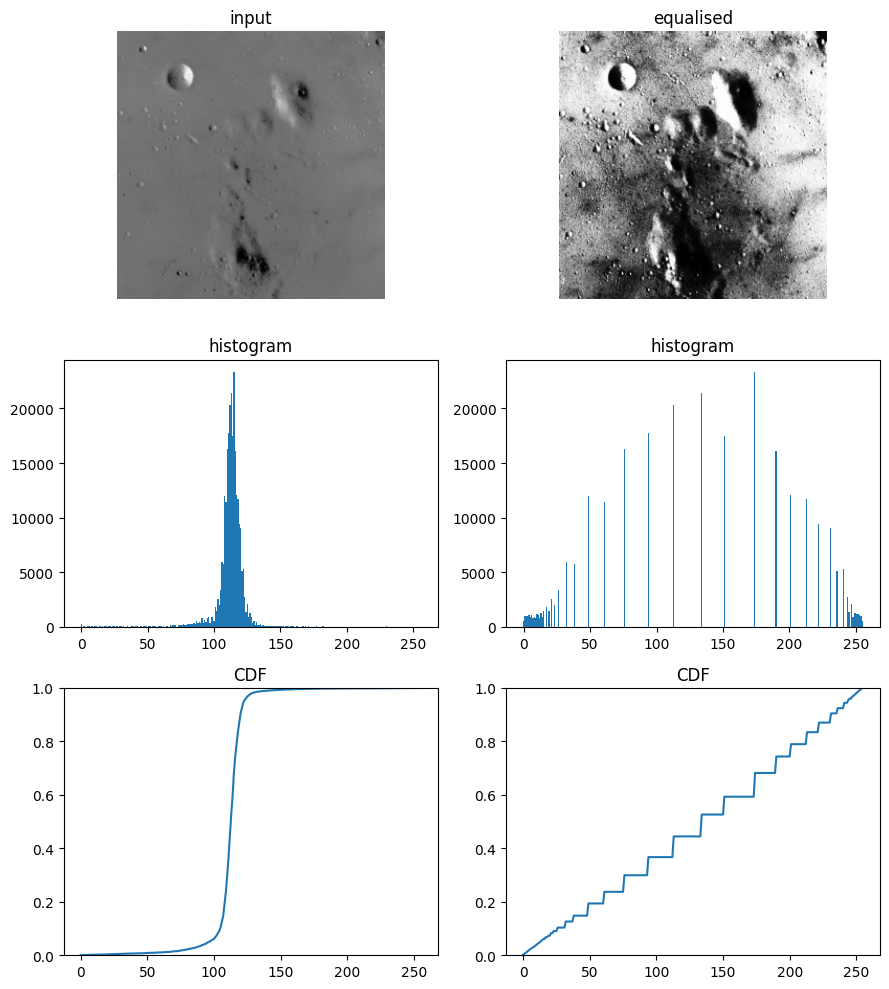

input   : levels used = 178  mean = 112.17
equalised: levels used = 49  mean = 133.89


In [3]:
eq_in = load_p4("equalization/input.png")
eq_out = equalise(eq_in)

show_hist_cdf([eq_in, eq_out], ["input", "equalised"])

print("input   : levels used =", len(np.unique(eq_in)), " mean =", round(eq_in.mean(), 2))
print("equalised: levels used =", len(np.unique(eq_out)), " mean =", round(eq_out.mean(), 2))

**(a) Your equalised histogram is not flat. Prove that it cannot be.**

T is a lookup table, so every pixel at input level v goes to the same output level T(v). That
means the pixels sitting in one input bin always move together. A bin can be merged with
another bin, but it can never be split.

A flat 256-bin histogram needs every bin to hold exactly N/256 pixels. The input bins have
whatever counts they have, and since I can only add counts together and never divide them, I
can only hit N/256 in every bin if the input counts already happen to add up that way. For a
real photograph they do not.

My numbers show the merging directly: the input uses 178 distinct levels and the output uses
49. T is non-decreasing, so wherever the CDF is flat (few pixels) several input levels round
to the same output level and get stacked into one tall bin. Nothing can pull them apart again.

The only case where the output is flat is when the input histogram is already uniform, and
then equalisation had nothing to do in the first place.

In [4]:
once = equalise(eq_in)
twice = equalise(once)

print("equalise(equalise(x)) == equalise(x) :", np.array_equal(twice, once))
print("max |difference| =", np.abs(twice.astype(int) - once.astype(int)).max())

equalise(equalise(x)) == equalise(x) : True
max |difference| = 0


**(b) Show that equalisation is exactly idempotent. Prove it, do not observe it.**

Write F for the input CDF and T(v) = round(255 F(v)). Let G be the CDF of the equalised
image, and I want to show that equalising a second time maps every level to itself, i.e.
round(255 G(T(v))) = T(v).

Take any input level v. Because T is non-decreasing, the input levels that land on the output
level T(v) form a run of consecutive levels. Call the last level of that run w, so T(w) = T(v)
and w is the largest level with that output.

Now count pixels. In the equalised image, the pixels at output levels <= T(v) are exactly the
pixels that were at input levels <= w, because T is non-decreasing and w is the top of the
run. Counting the same set of pixels two ways gives

    G(T(v)) = F(w).

Apply the second equalisation to level T(v):

    round(255 G(T(v))) = round(255 F(w)) = T(w) = T(v).

So every output level maps to itself, and the second pass is the identity. T(T(v)) = T(v) for
all v, which is exactly idempotence.

The code confirms it, with max |difference| = 0, but the argument above is why it has to be
zero and not merely small.

ramp: max |equalise(ramp) - ramp| = 1
ramp: pixels changed = 32768 of 65536


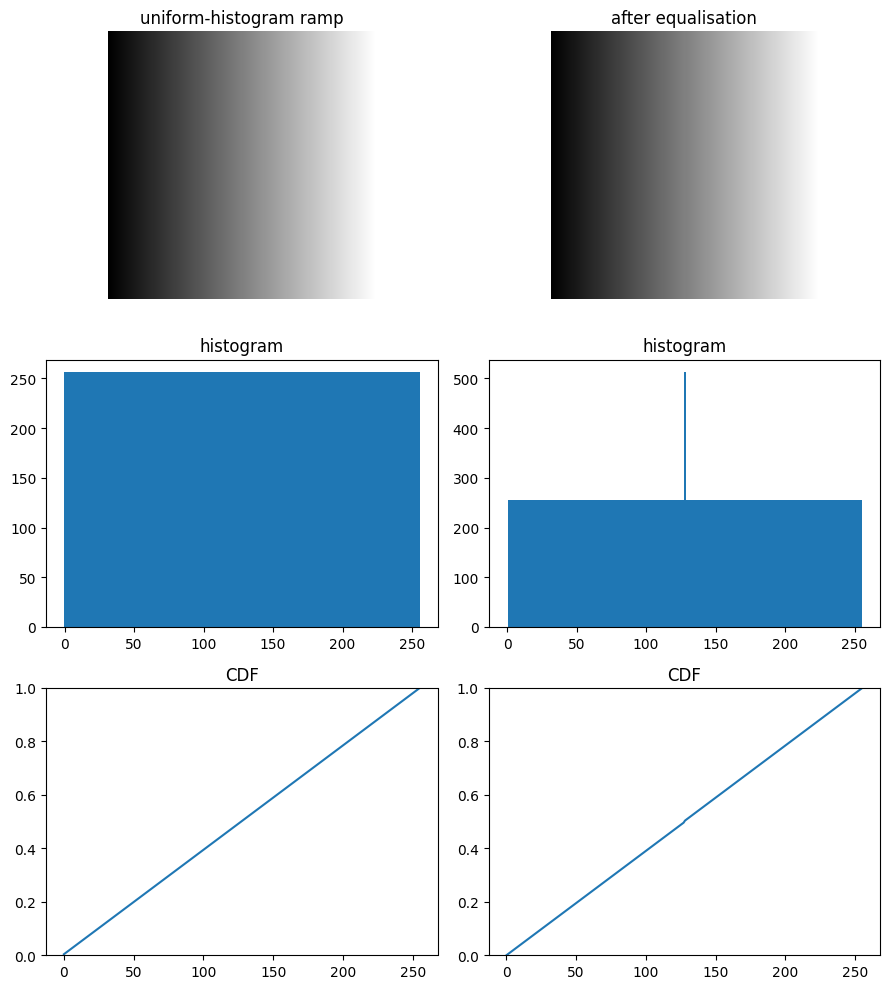

In [5]:
# an image whose CDF is already linear: equalisation has almost nothing to do
ramp = np.tile(np.arange(256, dtype=np.uint8), (256, 1))
ramp_eq = equalise(ramp)

print("ramp: max |equalise(ramp) - ramp| =", np.abs(ramp_eq.astype(int) - ramp.astype(int)).max())
print("ramp: pixels changed =", int((ramp_eq != ramp).sum()), "of", ramp.size)

show_hist_cdf([ramp, ramp_eq], ["uniform-histogram ramp", "after equalisation"])

**(c) Find or construct an image on which equalisation does essentially nothing, and explain
what property of its histogram causes that.**

I used a linear ramp, one column per grey level, so every level 0-255 occurs exactly the same
number of times. Equalising it changes nothing visible: the largest change is 1 grey level,
and the pixels that move do so only because of the rounding in T.

The property is that its histogram is already uniform, so its CDF is already a straight line
from 0 to 1. Equalisation works by using the CDF as the mapping curve, and when the CDF is a
straight line the mapping is T(v) = round(255 * v/255) = v, the identity.

This also follows from part (b). Any image that has already been equalised is a fixed point,
so an easy way to build such an image is to equalise anything once and feed the result back
in.

## 4.2 — Histogram matching and specification

### (a) Match one image to another's histogram

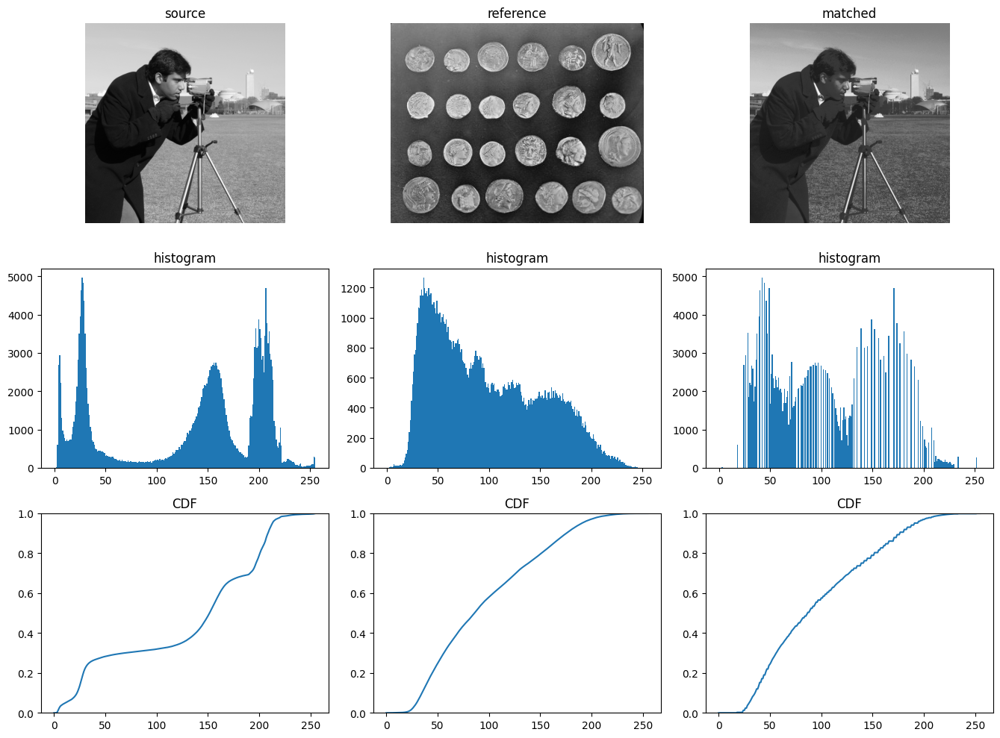

W1(source, reference)  = 40.775
W1(matched, reference) = 0.860


In [6]:
src = load_p4("matching/source.png")
ref = load_p4("matching/reference.png")
matched = specify(src, hist(ref))

show_hist_cdf([src, ref, matched], ["source", "reference", "matched"])

print(f"W1(source, reference)  = {wasserstein1(hist(src), hist(ref)):.3f}")
print(f"W1(matched, reference) = {wasserstein1(hist(matched), hist(ref)):.3f}")

### (b) Prescribed uniform and Gaussian targets

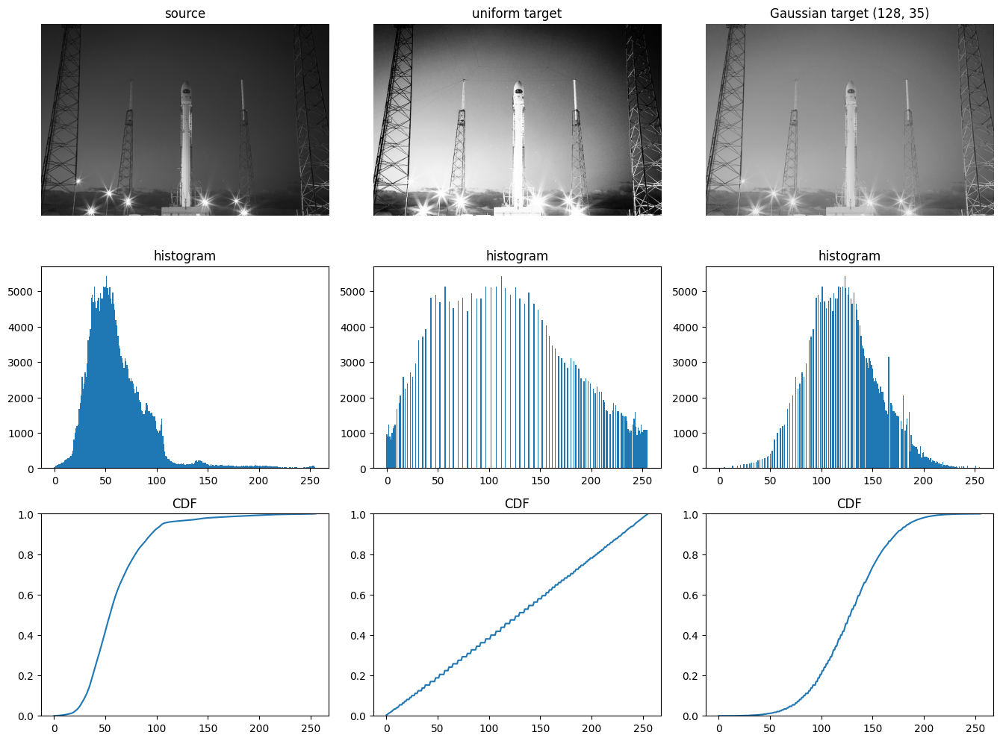

    target   W1 before   W1 after
   uniform      69.146      1.605
  gaussian      67.085      0.767

uniform specification vs plain equalisation:
  identical         : False
  pixels differing  : 72986 of 273280
  max |difference|  : 1


In [7]:
spec_src = load_p4("specification/source.png")

uniform_target = np.ones(256)
gaussian_target = np.exp(-0.5 * ((np.arange(256) - 128) / 35.0) ** 2)

out_uniform = specify(spec_src, uniform_target)
out_gaussian = specify(spec_src, gaussian_target)
plain_eq = equalise(spec_src)

show_hist_cdf([spec_src, out_uniform, out_gaussian],
              ["source", "uniform target", "Gaussian target (128, 35)"])

print(f"{'target':>10} {'W1 before':>11} {'W1 after':>10}")
for name, tgt, out in [("uniform", uniform_target, out_uniform),
                       ("gaussian", gaussian_target, out_gaussian)]:
    print(f"{name:>10} {wasserstein1(hist(spec_src), tgt):11.3f} {wasserstein1(hist(out), tgt):10.3f}")

print("\nuniform specification vs plain equalisation:")
print("  identical         :", np.array_equal(out_uniform, plain_eq))
print("  pixels differing  :", int((out_uniform != plain_eq).sum()), "of", spec_src.size)
print("  max |difference|  :", np.abs(out_uniform.astype(int) - plain_eq.astype(int)).max())

**Explain how uniform specification differs from plain equalisation, if at all.**

They are effectively the same operation.

Plain equalisation builds the LUT as T(v) = round(255 F(v)). Uniform specification takes a
flat target, forms its CDF (a straight line), and then matches by finding, for each v, the
output level whose target CDF first reaches F(v). Because the target CDF is a straight line,
that search is just F(v) * 255 read backwards, which is the same number equalisation computes
directly.

They only differ in how the number gets turned into an integer. Equalisation rounds to
nearest; my `searchsorted` picks the first level whose target CDF is at least F(v), which is
effectively a ceiling. So the two can disagree by one level.

Measured on `specification/source.png`: the two results are not byte-identical, 72986 of
273280 pixels differ, but the maximum difference is exactly 1 grey level. So it is the same
mapping, up to a rounding convention, and not a genuinely different operation.

### (c) Colour: per-channel against luminance only

In [8]:
def rgb_to_hsv(rgb):
    """Returns hue in degrees, saturation and value in [0, 1]."""
    f = rgb.astype(np.float64) / 255.0
    r, g, b = f[..., 0], f[..., 1], f[..., 2]
    mx, mn = f.max(-1), f.min(-1)
    d = mx - mn

    h = np.zeros_like(mx)
    m = d > 1e-12
    i = (mx == r) & m; h[i] = ((g - b)[i] / d[i]) % 6
    i = (mx == g) & m; h[i] = ((b - r)[i] / d[i]) + 2
    i = (mx == b) & m; h[i] = ((r - g)[i] / d[i]) + 4

    return h * 60.0, np.where(mx > 0, d / np.maximum(mx, 1e-12), 0.0), mx


def mean_hue_shift(before, after, sat_thresh=0.2):
    """Circular hue distance, averaged over pixels whose hue is defined."""
    h0, s0, _ = rgb_to_hsv(before)
    h1, _, _ = rgb_to_hsv(after)

    m = s0 > sat_thresh                      # near-achromatic pixels have no hue
    d = np.abs(h0[m] - h1[m])
    return float(np.mean(np.minimum(d, 360.0 - d)))


def apply_on_luma(rgb, fn):
    """Run a greyscale operator on luma only, scaling RGB to preserve chromaticity."""
    Y = to_luma(rgb)
    Y2 = fn(Y).astype(np.float64)
    scale = np.where(Y > 0, Y2 / np.maximum(Y, 1e-9), 0.0)[:, :, None]
    return np.clip(np.round(rgb.astype(np.float64) * scale), 0, 255).astype(np.uint8)

colour space         : HSV, hue in degrees
hue distance         : min(|dh|, 360 - |dh|)
saturation threshold : s > 0.2 (below this the hue is undefined)
pixels kept          : 48.1%

mean hue shift, per-channel RGB :  46.15 deg
mean hue shift, luminance only  :   0.66 deg


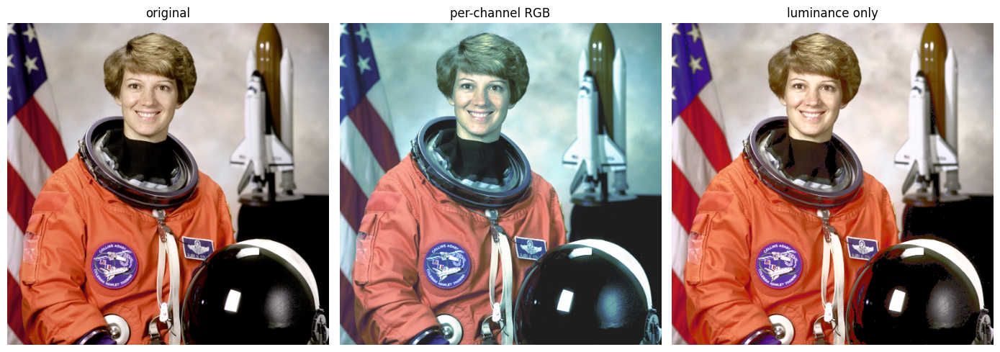

In [9]:
colour = load_p4("colour_source.png", "RGB")

per_channel = np.stack([equalise(colour[:, :, c]) for c in range(3)], axis=-1)
luma_only = apply_on_luma(colour, equalise)

SAT = 0.2
print("colour space         : HSV, hue in degrees")
print("hue distance         : min(|dh|, 360 - |dh|)")
print(f"saturation threshold : s > {SAT} (below this the hue is undefined)")
_, s0, _ = rgb_to_hsv(colour)
print(f"pixels kept          : {np.mean(s0 > SAT):.1%}\n")

print(f"mean hue shift, per-channel RGB : {mean_hue_shift(colour, per_channel, SAT):6.2f} deg")
print(f"mean hue shift, luminance only  : {mean_hue_shift(colour, luma_only, SAT):6.2f} deg")

fig, ax = plt.subplots(1, 3, figsize=(14, 5))
for a, im, t in zip(ax, [colour, per_channel, luma_only],
                    ["original", "per-channel RGB", "luminance only"]):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.tight_layout()
plt.show()

**Explain why the per-channel result is wrong, in terms of what equalisation assumes about its
input.**

Equalisation assumes its input is a single scalar channel, and that it is free to apply any
monotone curve to it. That assumption is fine for a greyscale image where the only thing a
pixel carries is brightness.

An RGB pixel does not work that way. Its colour is carried by the ratios between R, G and B,
not by the three values on their own. When I equalise the channels separately, each one gets
a different curve, because each channel has a different histogram. Different curves change R,
G and B by different amounts, so the ratios change, and so does the colour.

The numbers show it clearly. Mean hue shift is 46.15 degrees for per-channel equalisation
against 0.66 degrees for luminance only, measured over the 48.1% of pixels with saturation
above 0.2 (below that the hue is undefined so I exclude them). 46 degrees is a large shift,
big enough to move a colour into a different name.

The luminance-only version works because it puts the whole tone curve on Y and then scales R,
G and B by the same factor, which leaves the ratios alone and so leaves the hue alone. That
is the version that respects what equalisation actually assumes.

## 4.3 — Local histogram processing

Converted once to 8-bit BT.601 luma and reused throughout.

image: (1462, 2992)


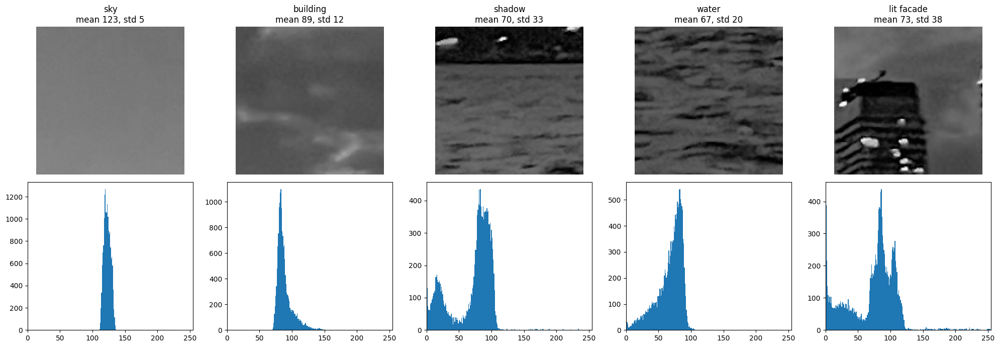

In [10]:
regions_rgb = load_p4("local_regions.png", "RGB")
Y = to_luma(regions_rgb)

print("image:", Y.shape)

patches = {"sky": (120, 1500), "building": (700, 900), "shadow": (1200, 400),
           "water": (1300, 2100), "lit facade": (600, 2400)}
size = 128

fig, ax = plt.subplots(2, len(patches), figsize=(4 * len(patches), 7))
for k, (name, (r, c)) in enumerate(patches.items()):
    p = Y[r:r + size, c:c + size]
    ax[0, k].imshow(p, cmap="gray", vmin=0, vmax=255)
    ax[0, k].set_title(f"{name}\nmean {p.mean():.0f}, std {p.std():.0f}")
    ax[0, k].axis("off")
    ax[1, k].bar(np.arange(256), hist(p), width=1.0)
    ax[1, k].set_xlim(0, 255)
plt.tight_layout()
plt.show()

**(a) Show that no single global mapping serves all of these patches.**

The five patches:

| patch | mean | std | range |
|---|---|---|---|
| sky | 122.7 | 5.1 | 109 - 137 |
| building | 88.5 | 12.3 | 69 - 164 |
| shadow | 69.7 | 32.6 | 0 - 254 |
| water | 67.4 | 19.9 | 0 - 109 |
| lit facade | 72.6 | 38.1 | 0 - 255 |

A global mapping is one curve applied everywhere, and its slope at a given input level is the
same no matter where in the image that level occurs.

The sky sits inside 109-137, only 28 levels wide, so to bring out any detail in it I need a
steep slope across that narrow band. But the lit facade already spans the full 0-255 and has
a std of 38.1, so it needs a gentle slope or it clips. Both of those demands apply to the same
input levels, and one curve cannot be steep and gentle at once.

The water sits in 0-109 and the shadow in 0-254, and both overlap the facade's range too, so
the conflict is not just between two patches. Whatever slope I choose near the middle of the
range, it is right for at most one of them. That is the argument for going local.

In [11]:
def ahe(img, tiles=8):
    """Plain tiled AHE: independent equalisation per tile, no clipping, no interpolation."""
    H, W = img.shape
    ry = np.linspace(0, H, tiles + 1).astype(int)
    rx = np.linspace(0, W, tiles + 1).astype(int)

    out = np.zeros_like(img)
    for i in range(tiles):
        for j in range(tiles):
            out[ry[i]:ry[i+1], rx[j]:rx[j+1]] = equalise(img[ry[i]:ry[i+1], rx[j]:rx[j+1]])

    return out


def clahe(img, tiles=8, clip=3.0, bins=256, target=None):
    """Clip each tile histogram at `clip` x its mean bin height, redistribute the
    excess, then bilinearly interpolate between the four surrounding tile LUTs.

    With `target` set, each tile is matched to that histogram instead of to a
    uniform one -- that is the local specification of part (e).
    """
    H, W = img.shape
    ry = np.linspace(0, H, tiles + 1).astype(int)
    rx = np.linspace(0, W, tiles + 1).astype(int)

    tcdf = None if target is None else cdf(np.asarray(target, dtype=np.float64))

    luts = np.zeros((tiles, tiles, bins))
    for i in range(tiles):
        for j in range(tiles):
            h = hist(img[ry[i]:ry[i+1], rx[j]:rx[j+1]], bins)

            if np.isfinite(clip):
                limit = clip * h.sum() / bins
                excess = np.maximum(h - limit, 0).sum()
                h = np.minimum(h, limit) + excess / bins

            c = np.cumsum(h) / h.sum()
            luts[i, j] = np.round(255 * c) if tcdf is None else \
                np.searchsorted(tcdf, c, side="left").clip(0, 255)

    # interpolation weights are relative to tile CENTRES, not tile edges
    cy = (ry[:-1] + ry[1:]) / 2.0
    cx = (rx[:-1] + rx[1:]) / 2.0

    y, x = np.arange(H), np.arange(W)
    iy = np.clip(np.searchsorted(cy, y) - 1, 0, tiles - 2)
    ix = np.clip(np.searchsorted(cx, x) - 1, 0, tiles - 2)

    # pixels outside the outermost centres clamp to the edge tiles
    wy = np.clip((y - cy[iy]) / (cy[iy + 1] - cy[iy]), 0, 1)[:, None]
    wx = np.clip((x - cx[ix]) / (cx[ix + 1] - cx[ix]), 0, 1)[None, :]

    I, J = iy[:, None], ix[None, :]
    top = (1 - wx) * luts[I, J, img] + wx * luts[I, J + 1, img]
    bot = (1 - wx) * luts[I + 1, J, img] + wx * luts[I + 1, J + 1, img]

    return np.round((1 - wy) * top + wy * bot).clip(0, 255).astype(np.uint8)

### (b) Plain tiled AHE

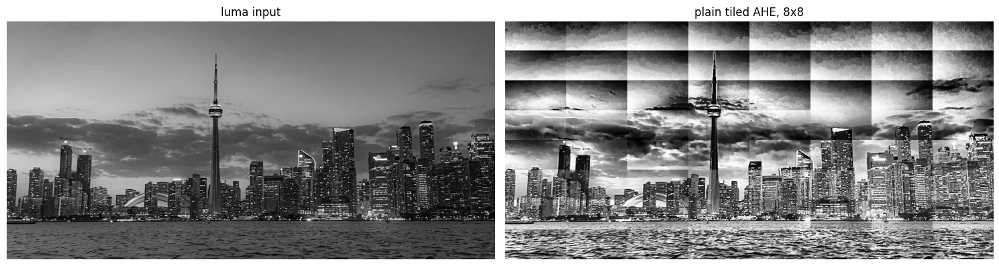

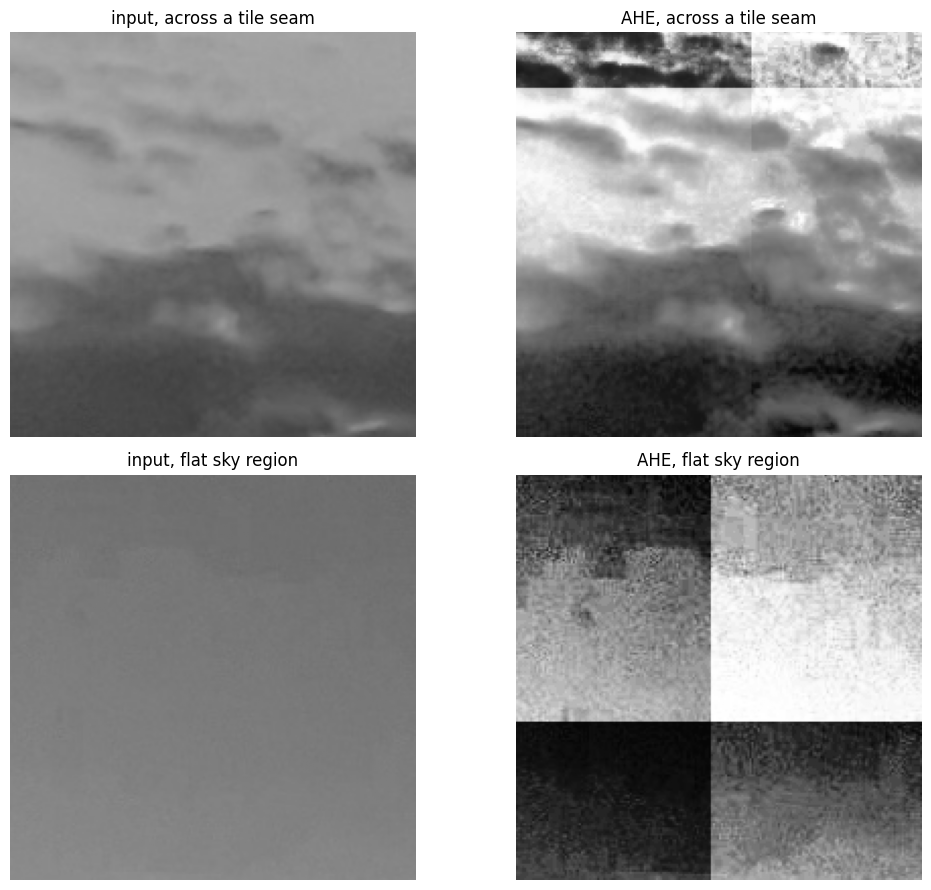

input std in flat crop : 7.77
AHE   std in flat crop : 75.51


In [12]:
ahe_out = ahe(Y, tiles=8)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].imshow(Y, cmap="gray", vmin=0, vmax=255); ax[0].set_title("luma input")
ax[1].imshow(ahe_out, cmap="gray", vmin=0, vmax=255); ax[1].set_title("plain tiled AHE, 8x8")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# crops showing the two failure modes
fig, ax = plt.subplots(2, 2, figsize=(11, 9))
seam = (np.s_[520:720], np.s_[1380:1580])       # spans a tile boundary
flat = (np.s_[60:260], np.s_[1400:1600])        # near-uniform sky
for k, (sl, name) in enumerate([(seam, "across a tile seam"), (flat, "flat sky region")]):
    ax[k, 0].imshow(Y[sl], cmap="gray", vmin=0, vmax=255)
    ax[k, 0].set_title(f"input, {name}")
    ax[k, 1].imshow(ahe_out[sl], cmap="gray", vmin=0, vmax=255)
    ax[k, 1].set_title(f"AHE, {name}")
    for a in ax[k]: a.axis("off")
plt.tight_layout(); plt.show()

print("input std in flat crop :", round(Y[flat].std(), 2))
print("AHE   std in flat crop :", round(ahe_out[flat].std(), 2))

**(b) Plain tiled AHE fails in two specific ways. Identify and explain both.**

**1. Blocking at the tile edges.** Each tile gets its own LUT built only from its own
histogram, and neighbouring tiles have different histograms, so they get different LUTs. Two
pixels with the same input value that happen to sit on opposite sides of a tile boundary come
out at different output values. Since the LUT changes abruptly at the boundary rather than
gradually, the seams show up as a visible grid. The crop across a tile seam above shows the
step clearly.

**2. Noise amplification in flat tiles.** Equalisation stretches whatever range a tile
contains to fill 0-255. A tile of open sky only spans a few levels, and almost all of that
spread is sensor noise, so the stretch multiplies the noise until it looks like real texture.
In my flat sky crop the std goes from 7.77 in the input to 75.51 after AHE, roughly ten times
larger. Nothing new has been revealed, the noise has just been made visible.

CLAHE fixes both: the clip limit caps how steep the tile mapping can get, which controls the
second problem, and interpolating between the four surrounding tile LUTs removes the
boundaries, which fixes the first.

### (c) CLAHE

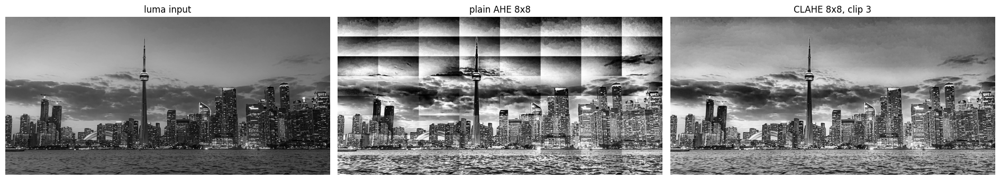

std  input 49.6  AHE 73.8  CLAHE 54.8


In [13]:
clahe_out = clahe(Y, tiles=8, clip=3.0)

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
for a, im, t in zip(ax, [Y, ahe_out, clahe_out],
                    ["luma input", "plain AHE 8x8", "CLAHE 8x8, clip 3"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

print("std  input", round(Y.std(), 1), " AHE", round(ahe_out.std(), 1),
      " CLAHE", round(clahe_out.std(), 1))

### (d) Ablation over clip limit and tile count

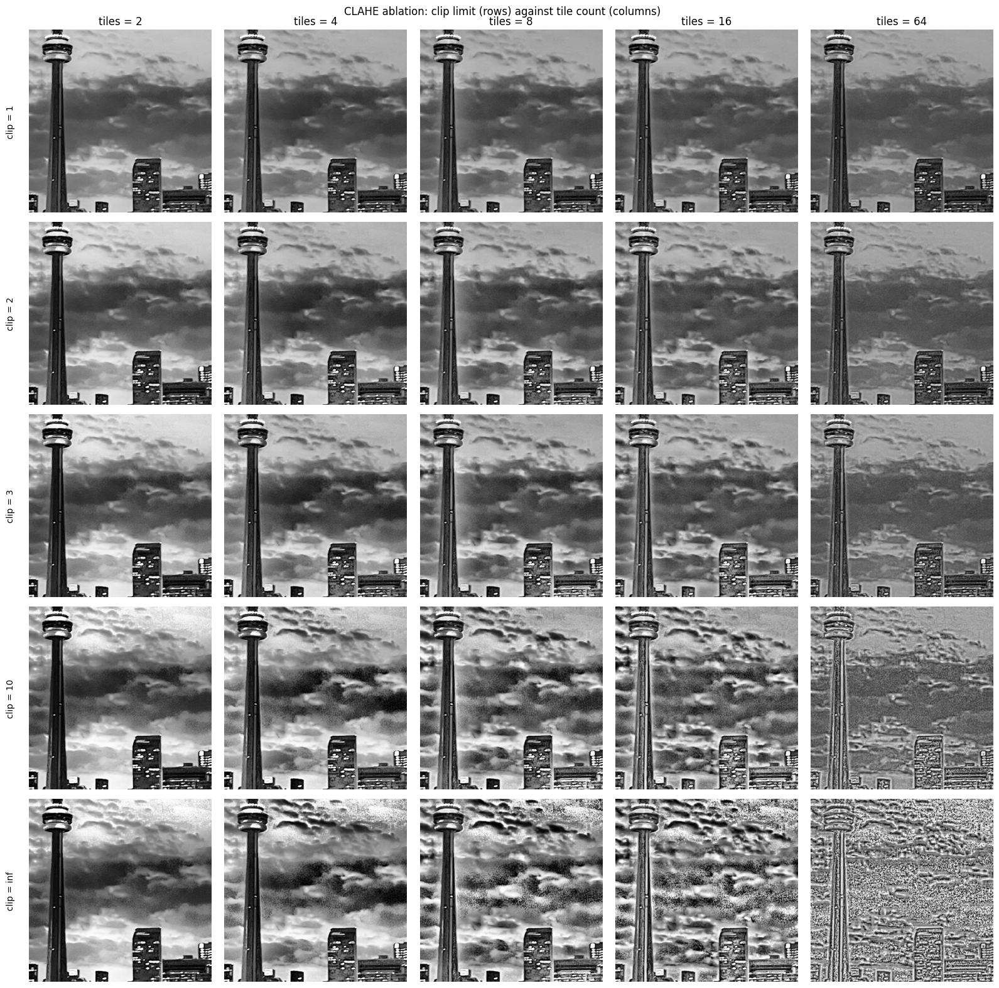

In [14]:
# a crop keeps the 25 runs quick; the same behaviour shows at full size
crop = Y[500:1012, 1200:1712]

clips = [1, 2, 3, 10, np.inf]
tile_counts = [2, 4, 8, 16, 64]

fig, ax = plt.subplots(len(clips), len(tile_counts), figsize=(16, 16))
for r, cl in enumerate(clips):
    for c, t in enumerate(tile_counts):
        ax[r, c].imshow(clahe(crop, tiles=t, clip=cl), cmap="gray", vmin=0, vmax=255)
        ax[r, c].axis("off")
        if r == 0:
            ax[r, c].set_title(f"tiles = {t}")
        if c == 0:
            ax[r, c].text(-0.1, 0.5, f"clip = {cl}", transform=ax[r, c].transAxes,
                          rotation=90, va="center", ha="center")
plt.suptitle("CLAHE ablation: clip limit (rows) against tile count (columns)")
plt.tight_layout(); plt.show()

**(d) Describe both degenerate ends of each axis.**

**Clip limit.** At clip = 1 the limit equals the mean bin height, so the clipping flattens the
tile histogram almost completely before the CDF is taken. A flat histogram gives a straight
CDF, which gives a LUT close to the identity, so the output looks nearly like the input and
almost no contrast is gained. At clip = infinity there is no clipping at all, so CLAHE reduces
to AHE with interpolation. The blocking is gone because of the interpolation, but the noise
amplification is back in full, which is why the sky in the bottom row looks so grainy.

**Tile count.** At tiles = 2 each tile covers a quarter of the image, so its histogram is
nearly the global histogram and the result is close to plain global equalisation. The local
detail the method exists for is not recovered. At tiles = 64 each tile is only about 23 x 47
pixels on this crop, which is too few pixels for a stable histogram. Neighbouring tiles then
get very different mappings from what is essentially noise, and the output goes blotchy with
halos around anything with strong contrast.

The usable settings are in the middle, and clip 2-3 with 8 tiles is what I used for the main
result.

### (e) Local histogram specification

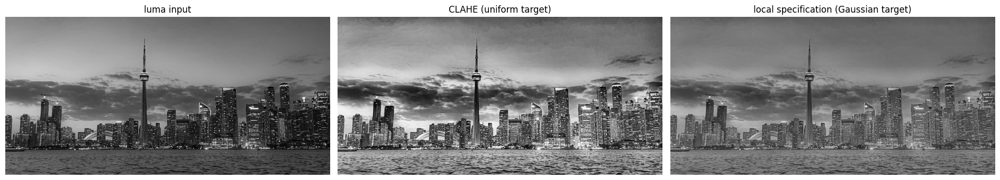

                                 std   W1 to target
CLAHE (uniform)                 54.8         19.862
local specification             30.7         12.244


In [15]:
# match every tile to a Gaussian target instead of a uniform one
local_target = np.exp(-0.5 * ((np.arange(256) - 110) / 45.0) ** 2)

spec_out = clahe(Y, tiles=8, clip=3.0, target=local_target)

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
for a, im, t in zip(ax, [Y, clahe_out, spec_out],
                    ["luma input", "CLAHE (uniform target)", "local specification (Gaussian target)"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

print(f"{'':28s} {'std':>7} {'W1 to target':>14}")
for name, im in [("CLAHE (uniform)", clahe_out), ("local specification", spec_out)]:
    print(f"{name:28s} {im.std():7.1f} {wasserstein1(hist(im), local_target):14.3f}")

**(e) Show a case where local specification beats CLAHE and say what extra information you had
to supply.**

CLAHE always aims each tile at a uniform histogram. That is a fixed goal and it is not always
the one I want. On this image it pushes the sky tiles hard, because a uniform target wants to
spread the sky's narrow range across the whole scale, and the sky ends up washed out and
noisy.

Using a Gaussian target with mean 110 and sigma 45 instead aims each tile at a distribution
with far fewer extreme values, so the sky is not forced to fill 0-255. The output std drops
from 54.8 to 30.7 and looks much closer to a normal photograph, and W1 to the target falls
from 19.862 to 12.244.

I should be honest that the W1 comparison is partly circular, since I picked the target and
then measured distance to it. The fair claim is not that specification has a lower error, but
that it gives me control: I decide what the output tonal distribution should be, instead of
accepting uniform.

**The extra information** is exactly that target histogram. CLAHE needs nothing beyond the
image. Local specification needs me to say what I want the result to look like, which in a
real workflow would come from a reference shot, a house style, or matching this frame to
another one. If I have no such reference, I have no target and the method has nothing to aim
at.

## 4.4 — Automatic correction

In [16]:
def auto_correct(rgb):
    """No per-image parameters: the anchors are estimated from the image itself.

    Auto-levels to the 1st and 99th luma percentiles, then an auto-gamma that
    puts the median at mid grey. RGB is scaled by the luma ratio so hue is kept.
    """
    Y = to_luma(rgb).astype(np.float64)

    lo, hi = np.percentile(Y, 1), np.percentile(Y, 99)
    stretched = np.clip((Y - lo) / max(hi - lo, 1e-6), 0, 1)

    median = float(np.clip(np.median(stretched), 0.02, 0.98))
    gamma = np.log(0.5) / np.log(median)

    Y2 = 255.0 * np.power(stretched, gamma)
    scale = np.where(Y > 0, Y2 / np.maximum(Y, 1e-9), 0.0)[:, :, None]

    return np.clip(np.round(rgb.astype(np.float64) * scale), 0, 255).astype(np.uint8)

In [17]:
exposures = [load_p4(f"exposure/ev{i}.png", "RGB") for i in range(5)]
corrected = [auto_correct(e) for e in exposures]


def pairwise_w1(imgs):
    d = [wasserstein1(hist(to_luma(imgs[i])), hist(to_luma(imgs[j])))
         for i in range(len(imgs)) for j in range(i + 1, len(imgs))]
    return float(np.mean(d)), float(np.max(d))


before, after = pairwise_w1(exposures), pairwise_w1(corrected)
print(f"{'':10s} {'mean W1':>9} {'max W1':>9}")
print(f"{'before':10s} {before[0]:9.2f} {before[1]:9.2f}")
print(f"{'after':10s} {after[0]:9.2f} {after[1]:9.2f}")

print(f"\n{'image':>6} {'luma std':>9} {'p1':>6} {'p99':>6}   (a flat output would be invalid)")
for i, c in enumerate(corrected):
    y = to_luma(c).astype(np.float64)
    print(f"ev{i:<4d} {y.std():9.1f} {np.percentile(y, 1):6.0f} {np.percentile(y, 99):6.0f}")

print("\nclipped pixels in the inputs (unrecoverable):")
for i, e in enumerate(exposures):
    y = to_luma(e)
    print(f"  ev{i}: {np.mean(y >= 255):5.1%} at 255, {np.mean(y <= 0):5.1%} at 0")

             mean W1    max W1
before         88.95    165.31
after          32.42     57.93

 image  luma std     p1    p99   (a flat output would be invalid)
ev0         76.5      0    253
ev1         76.8      0    253
ev2         76.7      0    254
ev3        113.3      0    255
ev4        120.0      0    255

clipped pixels in the inputs (unrecoverable):
  ev0:  0.0% at 255, 13.9% at 0
  ev1:  0.0% at 255, 12.9% at 0
  ev2:  0.1% at 255, 12.1% at 0
  ev3: 38.2% at 255, 11.0% at 0
  ev4: 56.8% at 255, 10.8% at 0


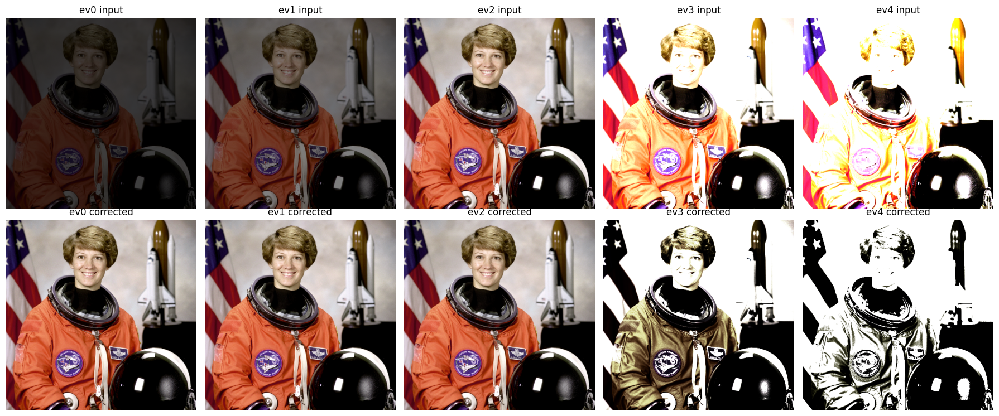

In [18]:
fig, ax = plt.subplots(2, 5, figsize=(18, 7.5))
for i, (e, c) in enumerate(zip(exposures, corrected)):
    ax[0, i].imshow(e); ax[0, i].set_title(f"ev{i} input"); ax[0, i].axis("off")
    ax[1, i].imshow(c); ax[1, i].set_title(f"ev{i} corrected"); ax[1, i].axis("off")
plt.tight_layout(); plt.show()

**State your estimator and give a concrete failure case.**

**Estimator.** Two steps, both measured from the image itself, no constants tuned per image.

1. Auto-levels: take the 1st and 99th percentile of the luma and stretch that range onto
   [0, 1]. Percentiles rather than min and max so a few stray pixels cannot set the scale.
2. Auto-gamma: take the median of the stretched luma and apply the gamma that sends it to
   0.5, i.e. gamma = log(0.5) / log(median). This anchors the midtone regardless of how dark
   or bright the input was.

Then R, G and B are scaled by the same luma ratio, so the correction changes brightness
without changing hue.

**Results.** Mean pairwise W1 falls from 88.95 to 32.42 and the max from 165.31 to 57.93. The
outputs are not flat, which the handout warns about: luma std is 76.5, 76.8, 76.7, 113.3 and
120.0, and the 1st-99th percentile ranges are all roughly 0-253 to 0-255.

**Failure case.** ev3 and ev4 are already clipped when I get them. 38.2% of ev3 and 56.8% of
ev4 sit at exactly 255. Everything above the sensor limit was thrown away before the file was
saved, and all those pixels now hold the same value. My correction is a monotone curve, so it
maps 255 to one output value and cannot separate them again. The information is gone. That is
why ev3 and ev4 keep a higher std than ev0-ev2 after correction, and why the pairwise
distances flatten out at 32 instead of going to zero. No parameter-free tone curve can fix
this, only a better exposure or a bracketed capture.

A second failure is a scene that is genuinely dark on purpose, a night shot for example. My
estimator assumes the median should end up at mid grey, so it would brighten the night into
something flat and grey and destroy the intended look.